# Milestone 2 – Exploratory Data Analysis
**Goal:** find which campaign features relate to success, to guide feature choice in Milestone 3.

Uses the clean dataset from Milestone 1 (`data/processed/kickstarter_us_clean.csv`).

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG = ROOT / "figures"; FIG.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid")

df = pd.read_csv(ROOT / "data/processed/kickstarter_us_clean.csv")
BASE = df["success"].mean()
print(f"{len(df):,} campaigns, overall success rate = {BASE:.1%}")

38,463 campaigns, overall success rate = 54.8%


## 1. Goal amount
Goals are very skewed (a few are in the millions), so I group them into ranges.

count       38463.0
mean        10468.0
std        154090.0
min             0.0
25%          1600.0
50%          4000.0
75%          8500.0
max      21474836.0
Name: goal, dtype: float64
             mean  size
goal_range             
<1k         0.690  6880
1k-2.5k     0.657  7915
2.5k-5k     0.567  9717
5k-10k      0.486  7159
10k-25k     0.367  4654
25k-50k     0.236  1333
50k+        0.130   805


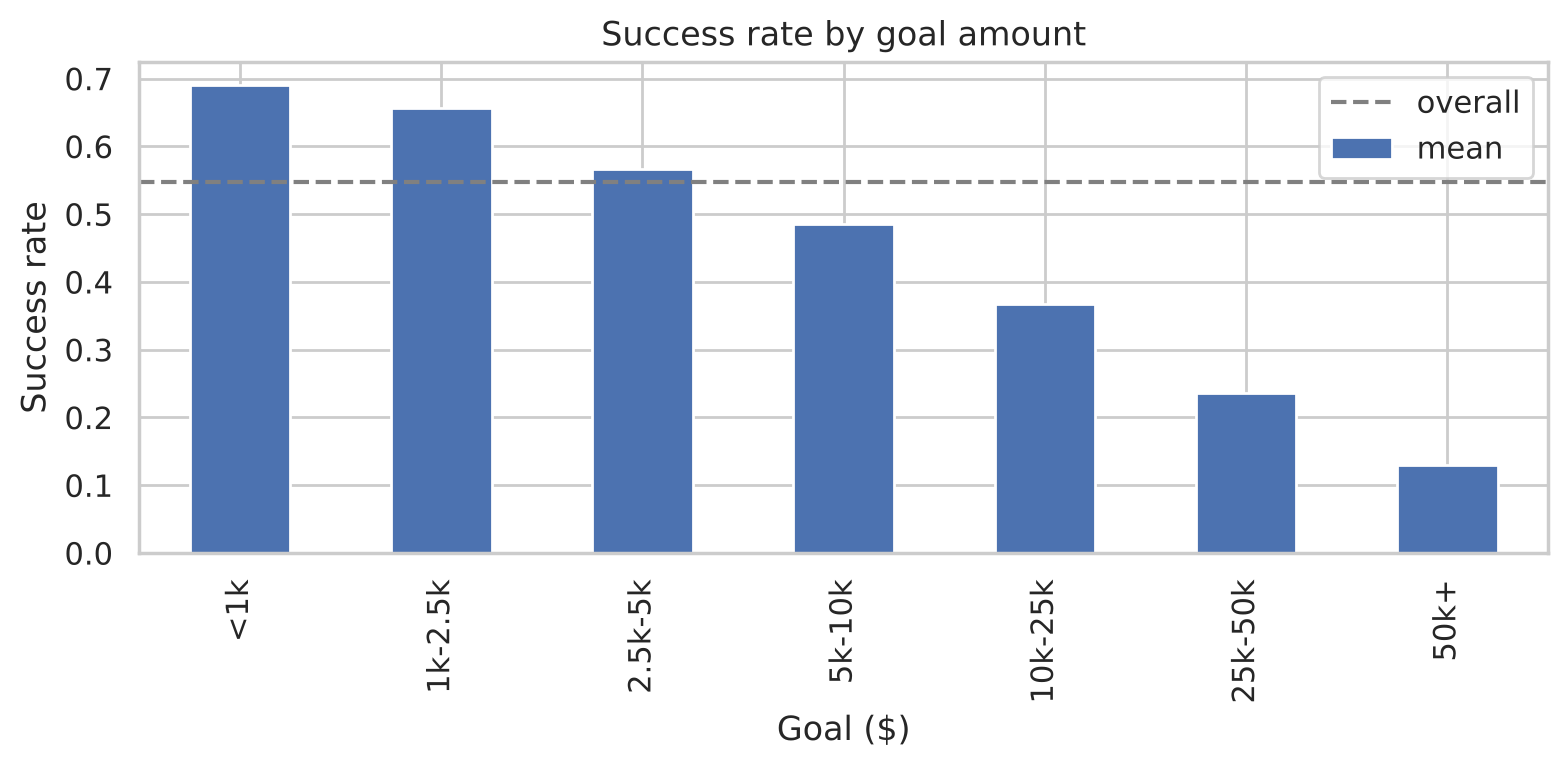

In [2]:
print(df["goal"].describe().round(0))
bins = [0, 1_000, 2_500, 5_000, 10_000, 25_000, 50_000, np.inf]
labels = ["<1k", "1k-2.5k", "2.5k-5k", "5k-10k", "10k-25k", "25k-50k", "50k+"]
df["goal_range"] = pd.cut(df["goal"], bins=bins, labels=labels)
goal_rate = df.groupby("goal_range", observed=True)["success"].agg(["mean", "size"])
print(goal_rate.round(3))

ax = goal_rate["mean"].plot(kind="bar", color="#4C72B0", figsize=(8, 4))
ax.axhline(BASE, ls="--", c="gray", label="overall")
ax.set(title="Success rate by goal amount", xlabel="Goal ($)", ylabel="Success rate"); ax.legend()
plt.tight_layout(); plt.savefig(FIG / "goal_vs_success.png", dpi=120); plt.show()

## 2. Campaign duration

                 mean   size
duration_range              
<15             0.677   1283
15-29           0.649   6156
30              0.537  10714
31-45           0.610   7720
46-60           0.498   6125
60+             0.416   6465


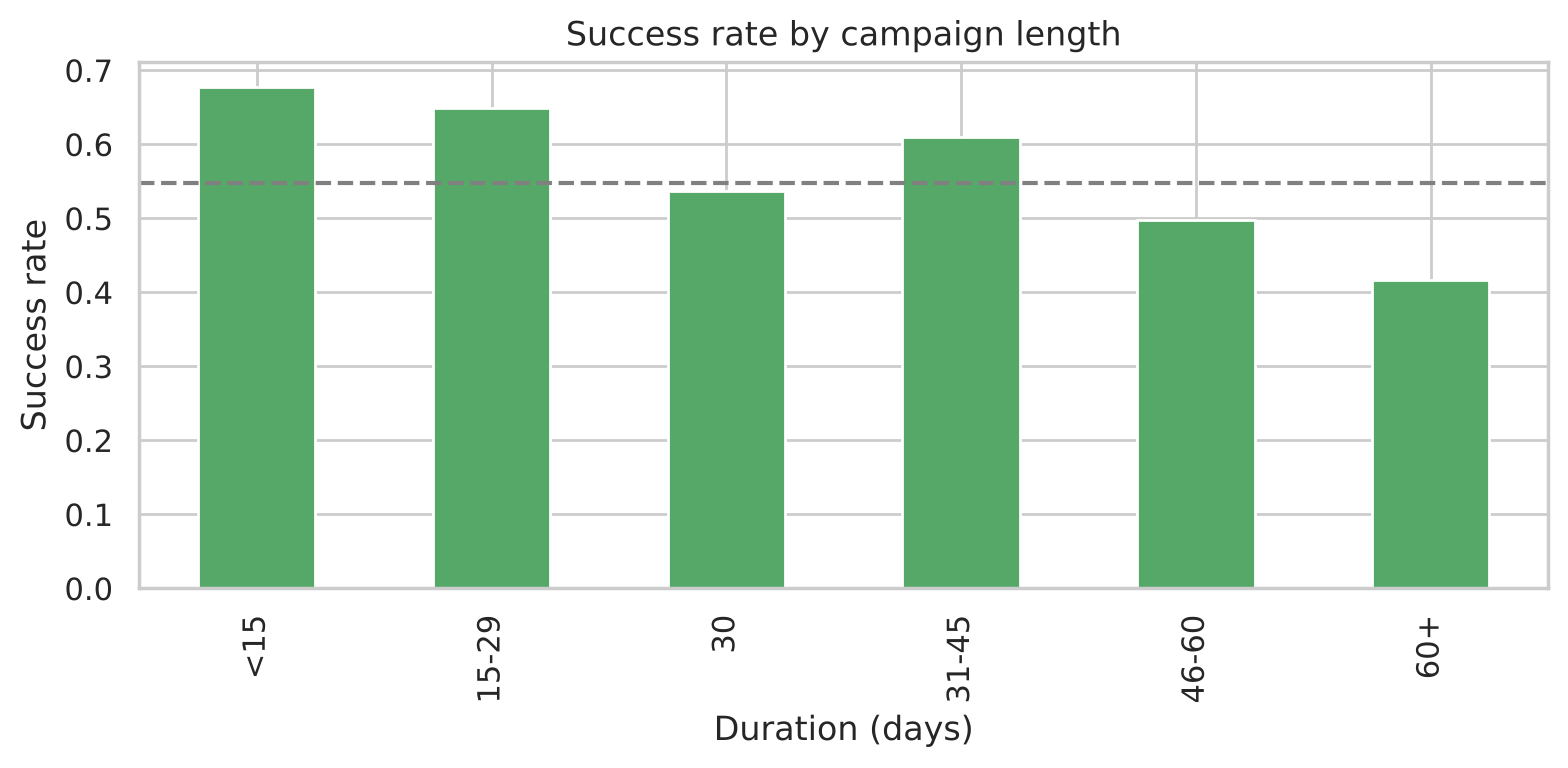

In [3]:
df["duration_range"] = pd.cut(df["duration"], bins=[0, 15, 30, 31, 45, 60, np.inf],
                              labels=["<15", "15-29", "30", "31-45", "46-60", "60+"], right=False)
dur_rate = df.groupby("duration_range", observed=True)["success"].agg(["mean", "size"])
print(dur_rate.round(3))

ax = dur_rate["mean"].plot(kind="bar", color="#55A868", figsize=(8, 4))
ax.axhline(BASE, ls="--", c="gray")
ax.set(title="Success rate by campaign length", xlabel="Duration (days)", ylabel="Success rate")
plt.tight_layout(); plt.savefig(FIG / "duration_vs_success.png", dpi=120); plt.show()

## 3. Updates (engagement)

                mean   size
updates_range              
0              0.204  12715
1-2            0.502   8214
3-5            0.737   7291
6-10           0.851   5859
10+            0.910   4384


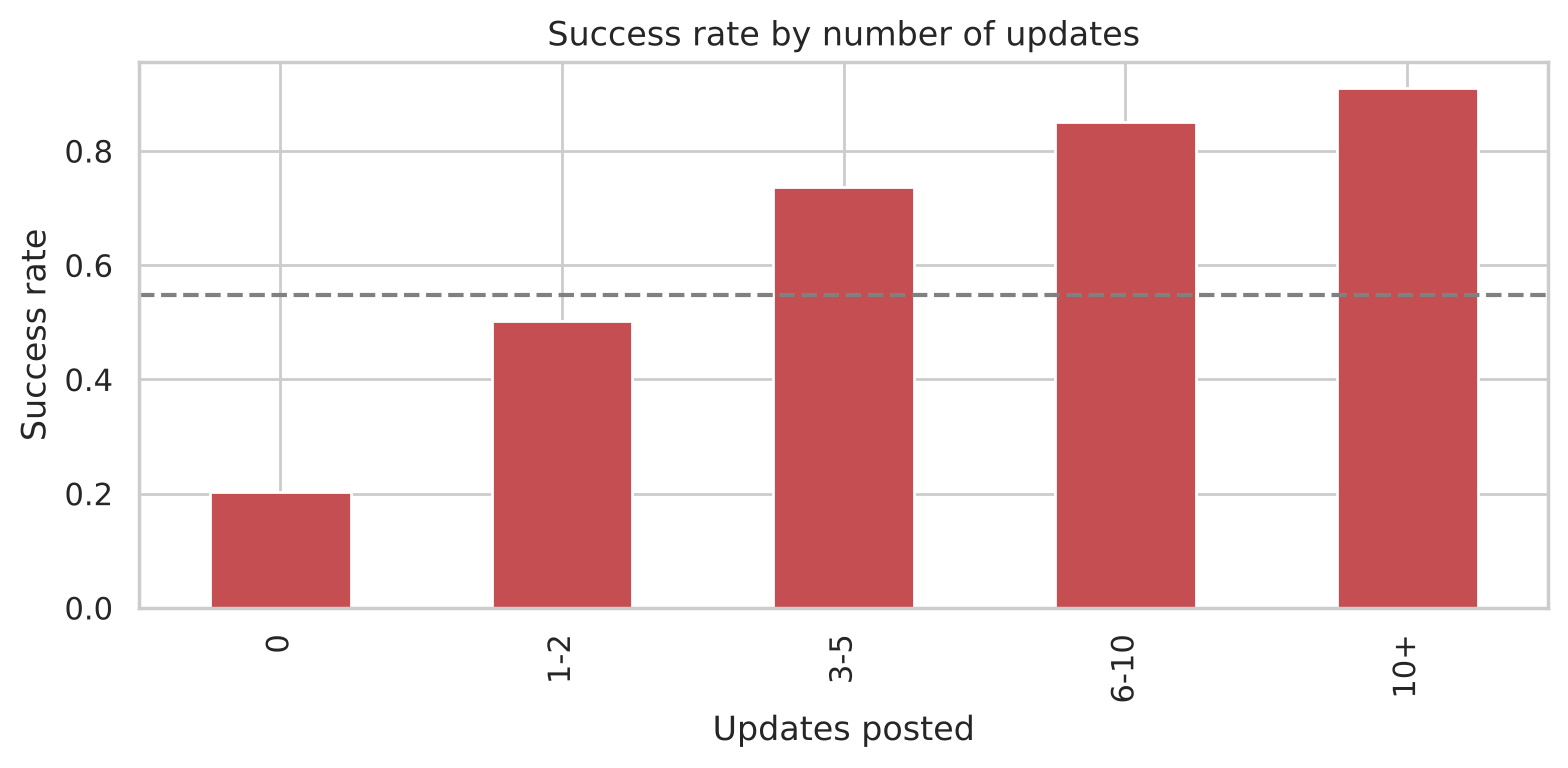

In [4]:
df["updates_range"] = pd.cut(df["updates"], bins=[-1, 0, 2, 5, 10, np.inf], labels=["0", "1-2", "3-5", "6-10", "10+"])
upd_rate = df.groupby("updates_range", observed=True)["success"].agg(["mean", "size"])
print(upd_rate.round(3))

ax = upd_rate["mean"].plot(kind="bar", color="#C44E52", figsize=(8, 4))
ax.axhline(BASE, ls="--", c="gray")
ax.set(title="Success rate by number of updates", xlabel="Updates posted", ylabel="Success rate")
plt.tight_layout(); plt.savefig(FIG / "updates_vs_success.png", dpi=120); plt.show()

## 4. Category and subcategory

               mean   size
category                  
Fashion       0.325    975
Technology    0.383    655
Publishing    0.393   3774
Games         0.433   1363
Photography   0.435   1109
Design        0.460   1450
Food          0.504   1243
Film & Video  0.511  11327
Comics        0.541    913
Art           0.565   3253
Music         0.678   9556
Theater       0.705   2196
Dance         0.761    649


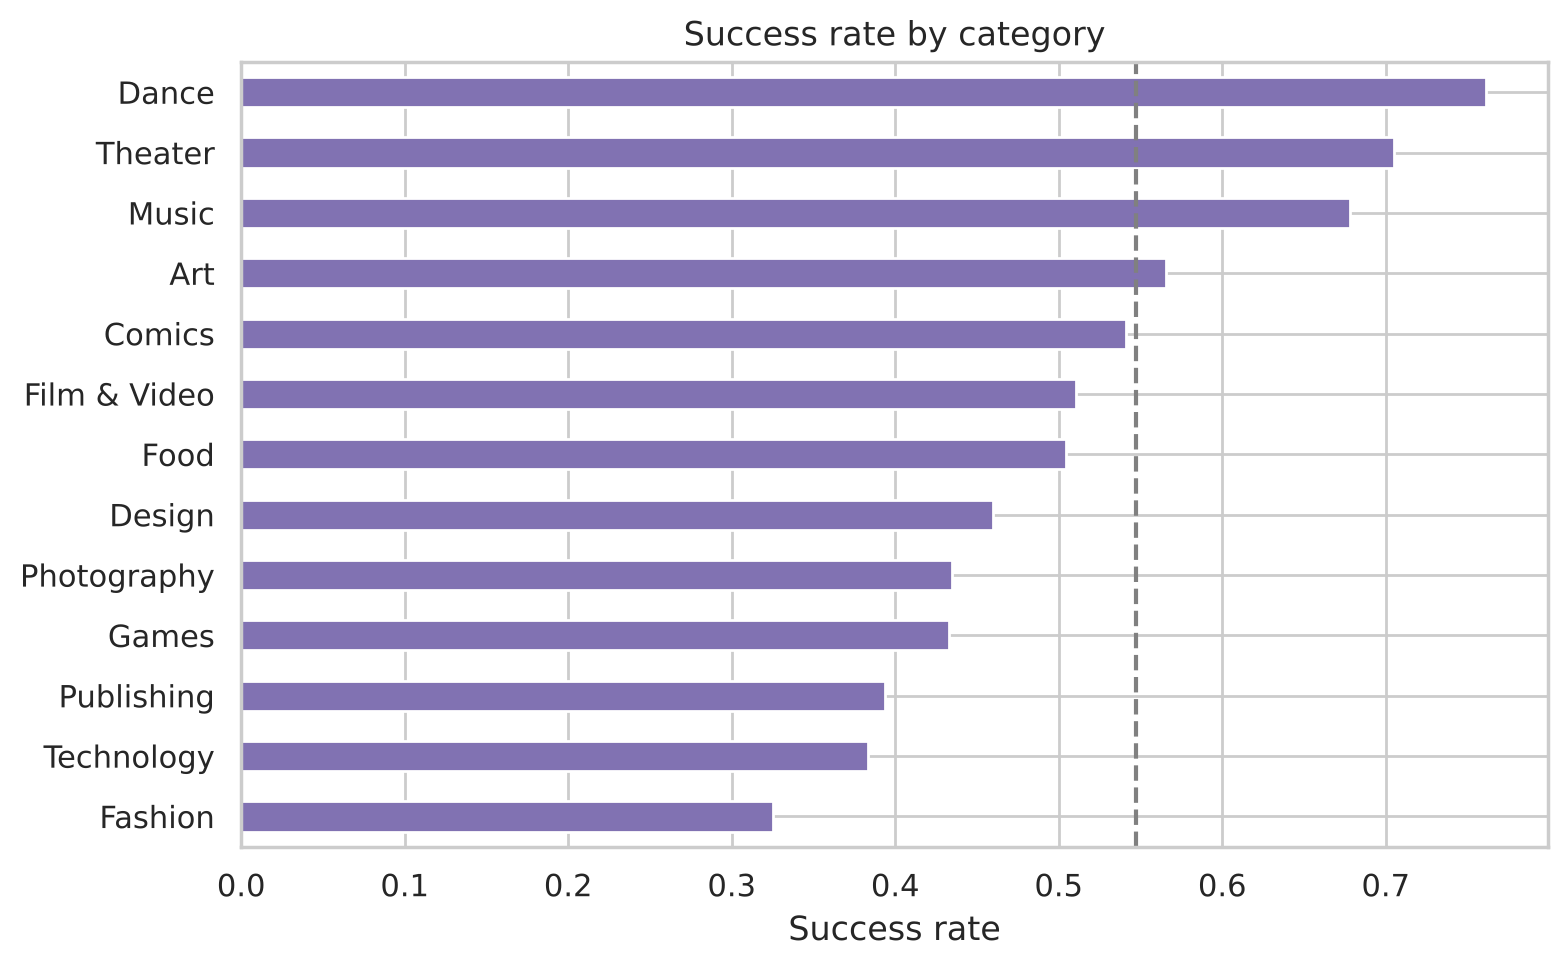


Subcategories with 200+ campaigns – lowest and highest success:
                  mean  size
subcategory                 
Video Games      0.308   686
Children's Book  0.321   514
Fashion          0.325   975
Technology       0.354   305
Nonfiction       0.364   788
Jazz             0.726   383
Country & Folk   0.745   940
Classical Music  0.746   393
Indie Rock       0.755  1732
Dance            0.761   649


In [5]:
cat_rate = df.groupby("category")["success"].agg(["mean", "size"]).sort_values("mean")
print(cat_rate.round(3))

ax = cat_rate["mean"].plot(kind="barh", color="#8172B2", figsize=(8, 5))
ax.axvline(BASE, ls="--", c="gray")
ax.set(title="Success rate by category", xlabel="Success rate", ylabel="")
plt.tight_layout(); plt.savefig(FIG / "category_vs_success.png", dpi=120); plt.show()

sub = df.groupby("subcategory")["success"].agg(["mean", "size"]).query("size >= 200").sort_values("mean")
print("\nSubcategories with 200+ campaigns – lowest and highest success:")
print(pd.concat([sub.head(5), sub.tail(5)]).round(3))

## 5. Location (state)

27 states with 300+ campaigns


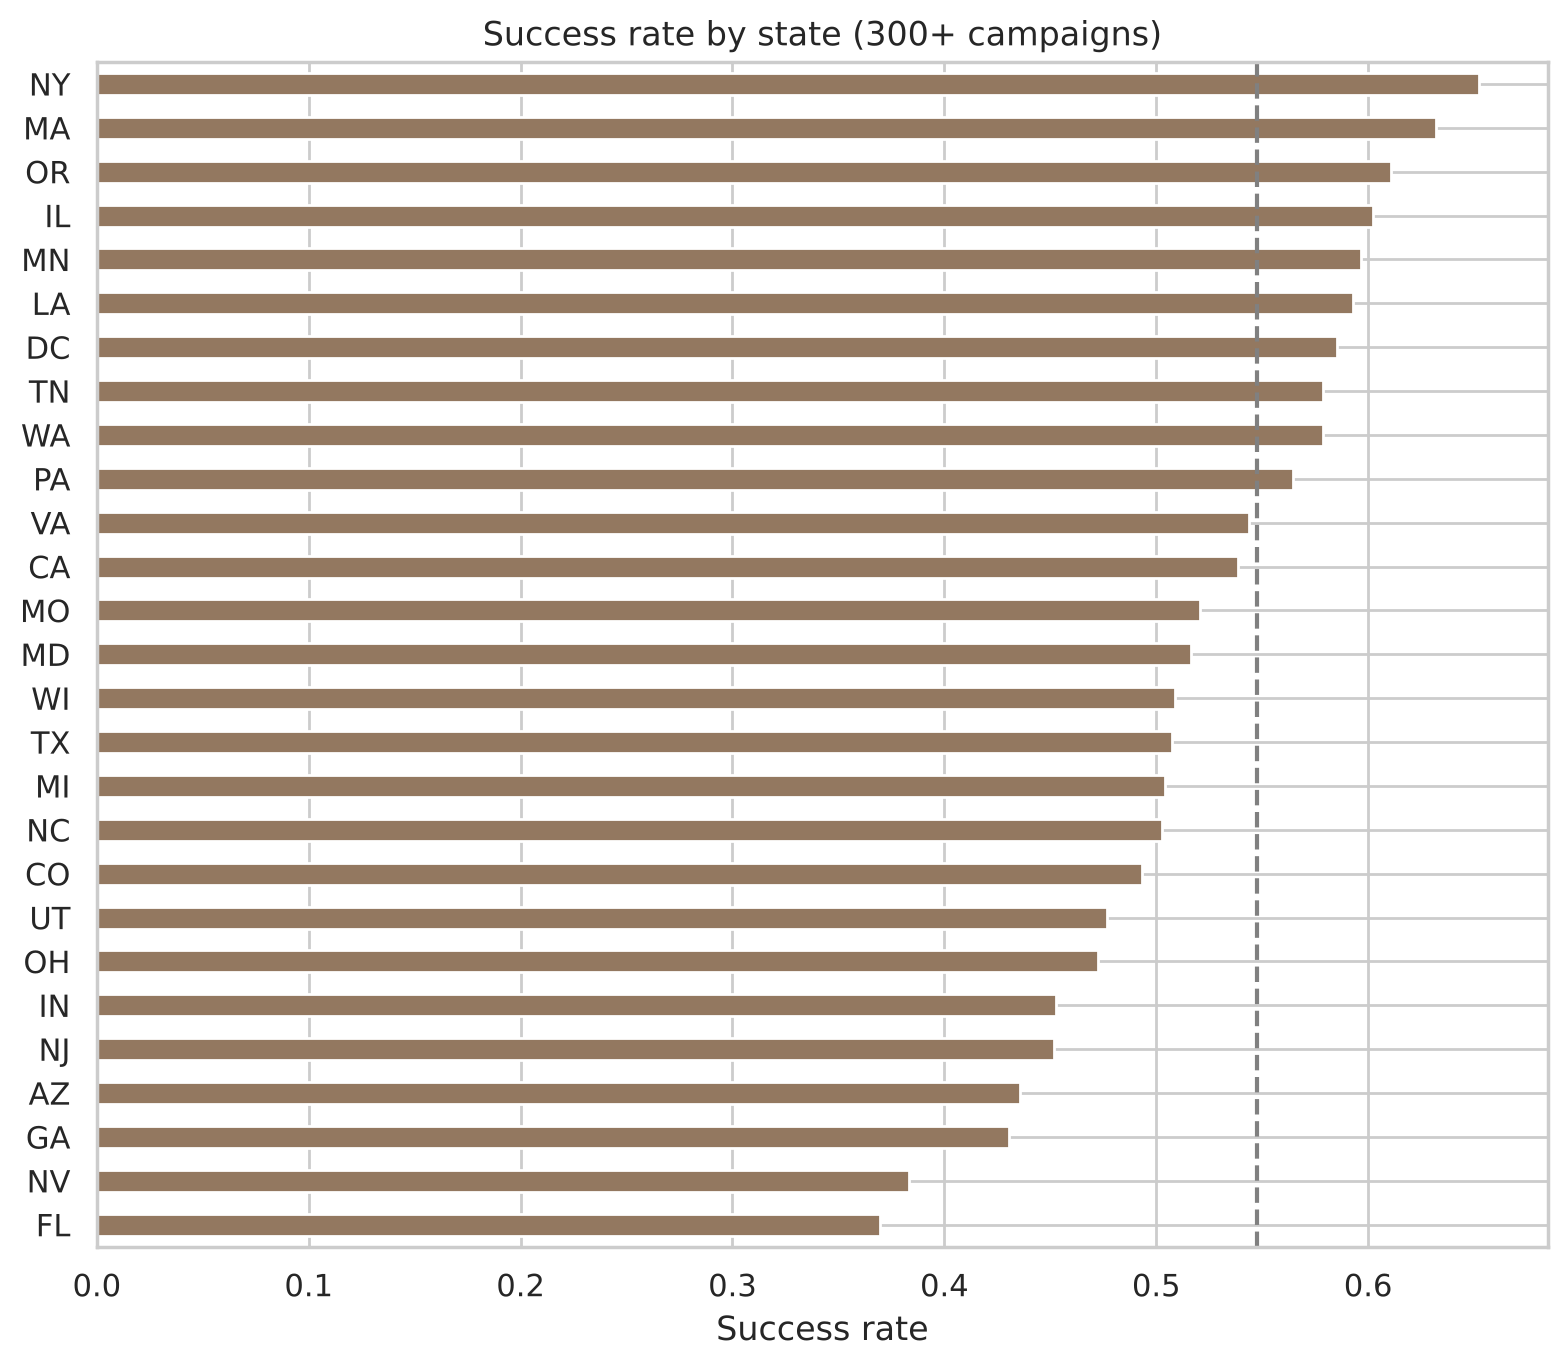

state
CA    8213
NY    6626
TX    1846
IL    1714
FL    1407
Name: count, dtype: int64


In [6]:
state_rate = df.groupby("state")["success"].agg(["mean", "size"]).query("size >= 300").sort_values("mean")
print(f"{len(state_rate)} states with 300+ campaigns")
ax = state_rate["mean"].plot(kind="barh", color="#937860", figsize=(8, 7))
ax.axvline(BASE, ls="--", c="gray")
ax.set(title="Success rate by state (300+ campaigns)", xlabel="Success rate", ylabel="")
plt.tight_layout(); plt.savefig(FIG / "state_vs_success.png", dpi=120); plt.show()
print(df["state"].value_counts().head(5))

## 6. Reward levels

               mean   size
levels_range              
1-3           0.361   3426
4-6           0.506  11044
7-9           0.565  13449
10-12         0.594   6591
13+           0.689   3953


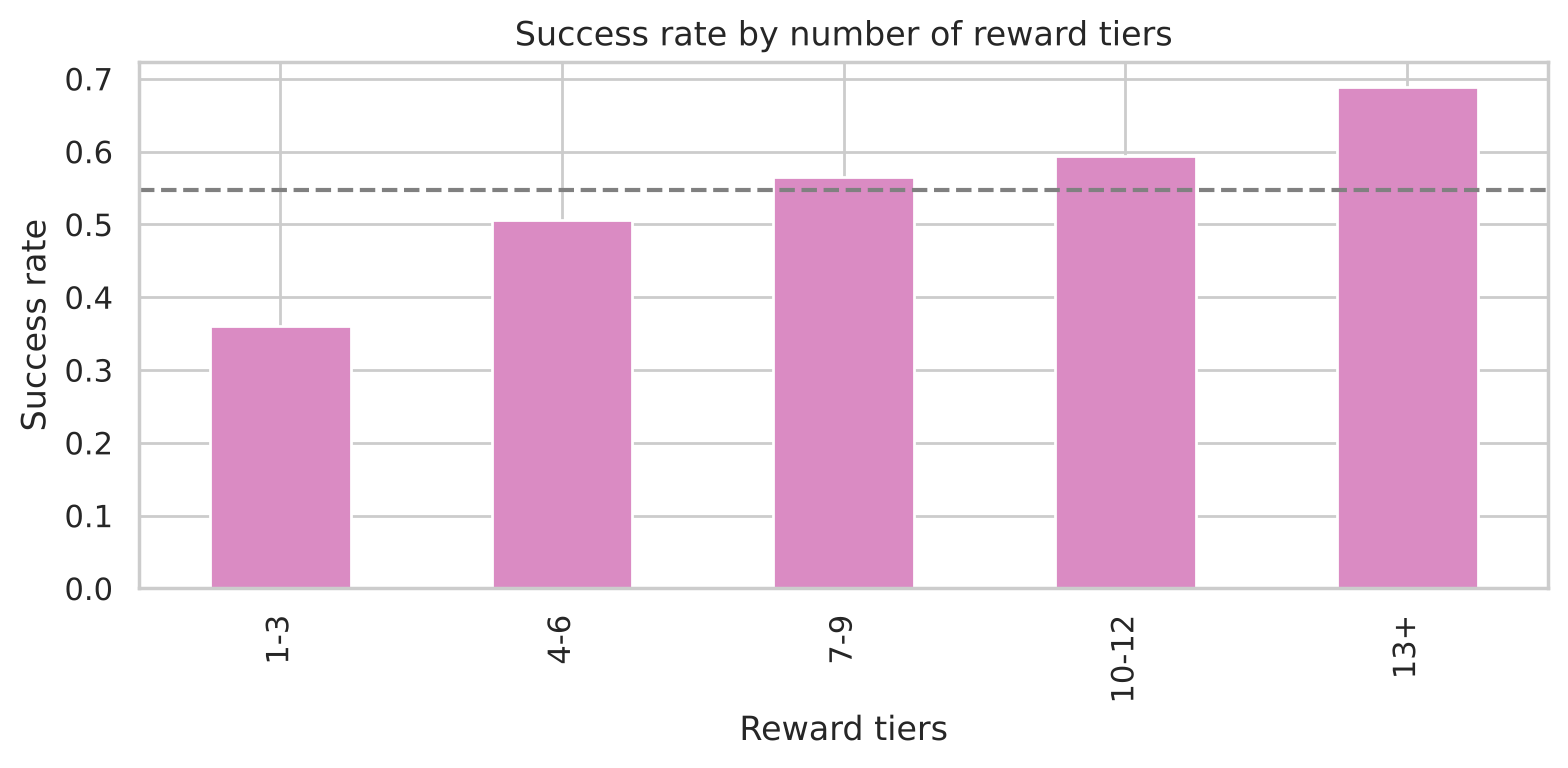

In [7]:
df["levels_range"] = pd.cut(df["levels"], bins=[0, 3, 6, 9, 12, np.inf], labels=["1-3", "4-6", "7-9", "10-12", "13+"])
lvl_rate = df.groupby("levels_range", observed=True)["success"].agg(["mean", "size"])
print(lvl_rate.round(3))

ax = lvl_rate["mean"].plot(kind="bar", color="#DA8BC3", figsize=(8, 4))
ax.axhline(BASE, ls="--", c="gray")
ax.set(title="Success rate by number of reward tiers", xlabel="Reward tiers", ylabel="Success rate")
plt.tight_layout(); plt.savefig(FIG / "levels_vs_success.png", dpi=120); plt.show()

## 7. Correlation summary
Spearman correlation (rank-based) is used because goal and the other numbers are skewed. Leaky columns are shown for comparison only.

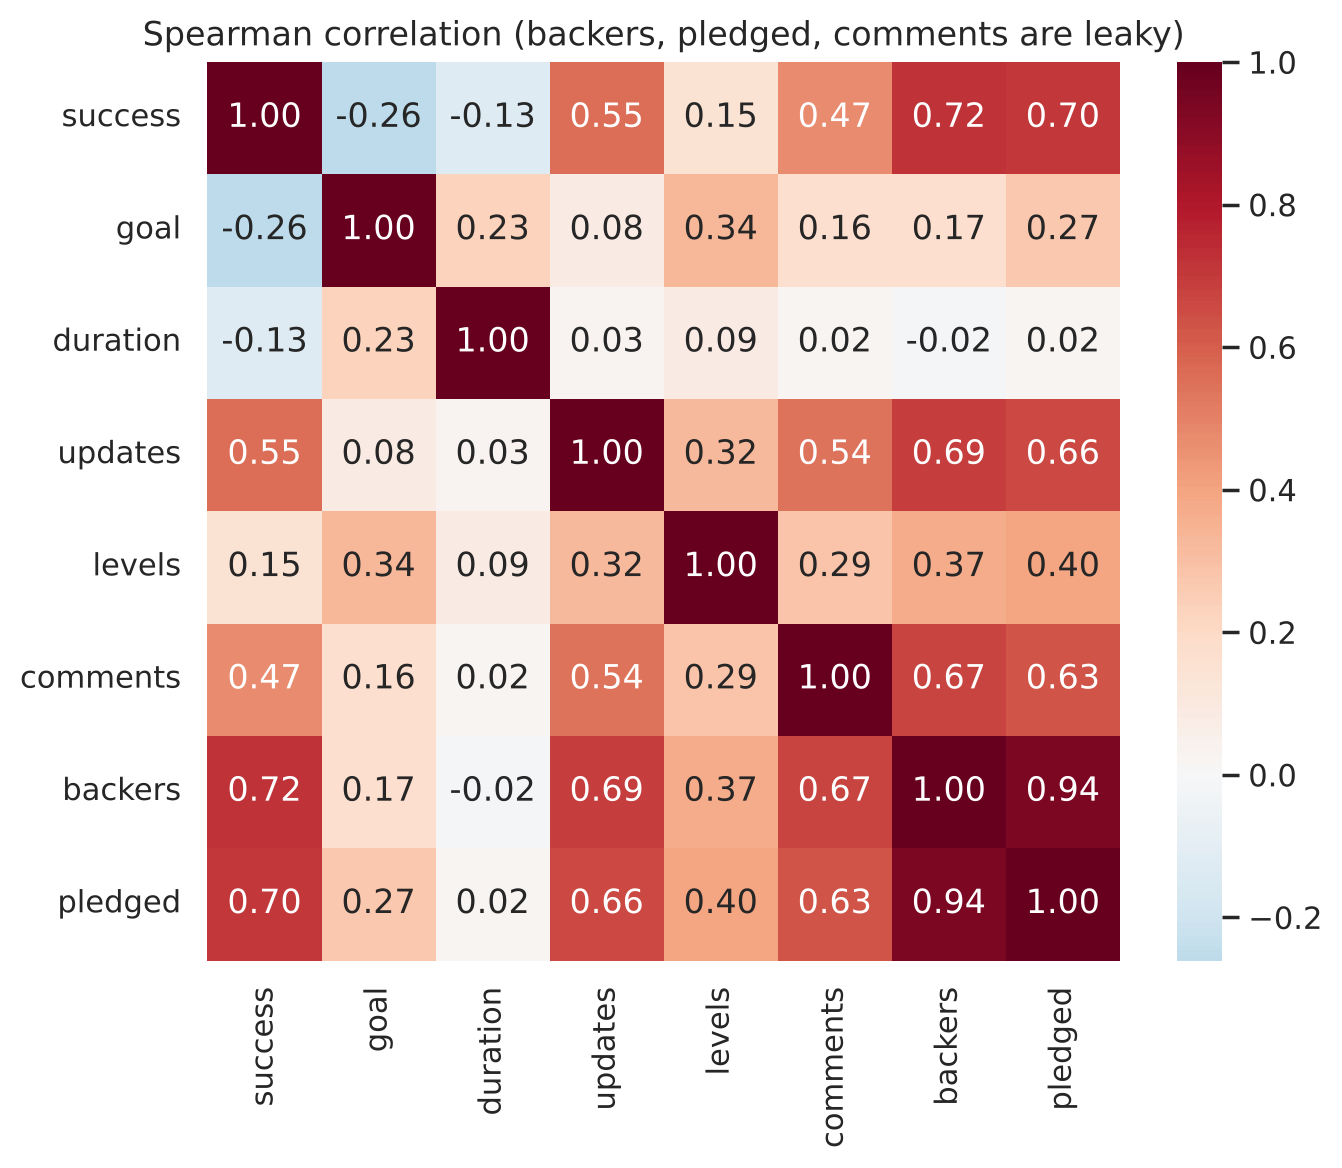

goal       -0.261
duration   -0.129
levels      0.147
comments    0.469
updates     0.552
pledged     0.704
backers     0.722
Name: success, dtype: float64

In [8]:
cols = ["success", "goal", "duration", "updates", "levels", "comments", "backers", "pledged"]
corr = df[cols].corr(method="spearman")
plt.figure(figsize=(7, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0)
plt.title("Spearman correlation (backers, pledged, comments are leaky)")
plt.tight_layout(); plt.savefig(FIG / "correlation_heatmap.png", dpi=120); plt.show()
corr["success"].drop("success").sort_values().round(3)

## Key findings
1. **Smaller goals succeed far more often.** Success falls steadily from about 69% for goals under $1k to about 13% for goals of $50k+. Goal is the strongest launch-time predictor (Spearman ρ ≈ −0.26).
2. **Shorter campaigns do better.** Campaigns under 30 days succeed about 65% of the time, versus about 42% for those over 60 days. Long campaigns may signal less urgency or less planning.
3. **Updates have the strongest link to success, but there's a catch.** Success rises from about 20% with 0 updates to about 91% with 10+. Updates are posted *during* the campaign, so this is partly leakage. Milestone 3 will test models with and without `updates`.
4. **Category matters.** Dance, Theater and Music succeed most (68–76%). Fashion, Technology and Publishing succeed least (32–39%).
5. **More reward tiers go with higher success.** Success is about 36% with 1–3 tiers and about 69% with 13+, which suggests well-planned campaigns offer more options.
6. **Location matters less.** California and New York account for about 38% of campaigns. State success rates vary, but less than category or goal.

**Next (Milestone 3):** baseline Logistic Regression → Random Forest, KNN and XGBoost, evaluated on accuracy, precision, recall, F1 and ROC-AUC, with and without `updates`. All figures are saved in `figures/`.